# effect of fu,mic (https://doi.org/10.1093/database/baae063)

Valid rows: 1376
Eligible groups with >= 2 concentrations: 180

Top 20 ranked by fu_range = fu_max - fu_min:

                        rank  n_conc  n_raw  conc_min  conc_max  fu_mean  fu_sd  fu_min  fu_max  conc_fold  fu_range
group                                                                                                               
Imipramine | human         1       7     25     0.025      2.00    0.489  0.274   0.130   0.940     80.000     0.810
Phenytoin | human          2       5      9     0.250      2.00    0.757  0.307   0.250   1.000      8.000     0.750
Levofloxacin | human       3       2      2     0.250      0.50    0.645  0.502   0.290   1.000      2.000     0.710
Chlorpromazine | human     4       6     21     0.025      1.00    0.234  0.262   0.060   0.750     40.000     0.690
Midazolam | human          5       9     23     0.025      1.49    0.748  0.211   0.336   1.000     59.600     0.664
Clozapine | human          6       6     13     0.025      1.00    0.51

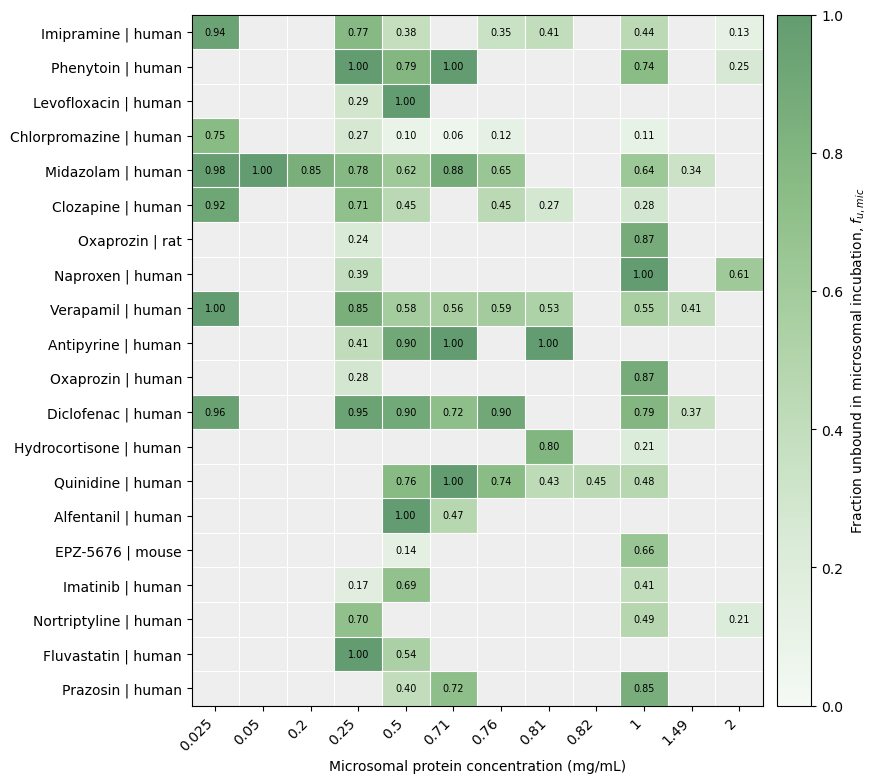

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

P = Path("./nonspecific_binding_dataset/Krumpholz_et_al_fu_dataset.xlsx")
TOP, MIN_CONC = 20, 2

df = pd.read_excel(P, sheet_name="Microsomes")
df.columns = df.columns.str.strip()
df["fu"] = pd.to_numeric(df["fu mean"], errors="coerce")
df["conc"] = pd.to_numeric(df["mg/ml"], errors="coerce")
df["group"] = df["Compound"].astype("string").str.strip() + " | " + df["species"].astype("string").str.strip()

d = df[df["fu"].between(0, 1)
    & df["conc"].gt(0)
    & df["group"].notna()
].copy()

# Average repeated measurements at each compound/species/concentration.
a = d.groupby(["group", "conc"], as_index=False).agg(
    fu=("fu", "mean"),
    n_rep=("fu", "size"),
)

stats = a.groupby("group").agg(
    n_conc=("conc", "nunique"),
    n_raw=("n_rep", "sum"),
    conc_min=("conc", "min"),
    conc_max=("conc", "max"),
    fu_mean=("fu", "mean"),
    fu_sd=("fu", "std"),
    fu_min=("fu", "min"),
    fu_max=("fu", "max"),
)
stats["conc_fold"] = stats["conc_max"] / stats["conc_min"]
stats["fu_range"] = stats["fu_max"] - stats["fu_min"]

top = (
    stats.query("n_conc >= @MIN_CONC")
    .sort_values(["fu_range", "n_conc"], ascending=[False, False])
    .head(TOP)
    .copy()
)
top.insert(0, "rank", range(1, len(top) + 1))

print(f"Valid rows: {len(d)}")
print(
    f"Eligible groups with >= {MIN_CONC} concentrations: "
    f"{(stats.n_conc >= MIN_CONC).sum()}"
)
print(f"\nTop {len(top)} ranked by fu_range = fu_max - fu_min:\n")
print(top.round(3).to_string())

if top.empty:
    raise ValueError("No compound/species groups meet the concentration requirement.")

p = (
    a[a["group"].isin(top.index)]
    .pivot(index="group", columns="conc", values="fu")
    .reindex(top.index)
    .sort_index(axis=1)
)

cmap = LinearSegmentedColormap.from_list(
    "soft_green",
    ["#f4f9f4", "#d8ead5", "#b3d5ac", "#8abc85", "#639c70"],
)
cmap.set_bad("#eeeeee")

fig, ax = plt.subplots(
    figsize=(max(9, 0.75 * len(p.columns)), max(5, 0.42 * len(p)))
)

im = ax.imshow(np.ma.masked_invalid(p.to_numpy()), aspect="auto", vmin=0, vmax=1, cmap=cmap)

ax.set_xticks(
    range(len(p.columns)),
    [f"{x:g}" for x in p.columns],
    rotation=45,
    ha="right",
)
ax.set_yticks(range(len(p)), p.index)
ax.set_xlabel("Microsomal protein concentration (mg/mL)")
ax.tick_params(axis="both", colors="black")

# Black numeric annotations.
for i in range(len(p)):
    for j in range(len(p.columns)):
        v = p.iloc[i, j]
        if pd.notna(v):
            ax.text(
                j, i, f"{v:.2f}",
                ha="center", va="center",
                fontsize=7, color="black",
            )

ax.set_xticks(np.arange(-0.5, len(p.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(p), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Fraction unbound in microsomal incubation, $f_{u,mic}$")
cbar.ax.tick_params(colors="black")

fig.tight_layout(rect=(0, 0.055, 1, 1))
plt.show()

In [4]:
# Overall trend across all eligible compound/species groups
trend = (
    a.sort_values("conc")
    .groupby("group")
    .agg(
        n_conc=("conc", "nunique"),
        fu_low=("fu", "first"),
        fu_high=("fu", "last"),
    )
)

trend = trend[trend["n_conc"] >= MIN_CONC].copy()

trend["delta_fu"] = trend["fu_high"] - trend["fu_low"]

# Small differences treated as approximately unchanged
EPS = 0.02

trend["direction"] = np.select(
    [
        trend["delta_fu"] < -EPS,
        trend["delta_fu"] > EPS,
    ],
    ["Decreasing", "Increasing"],
    default="Approximately unchanged",
)

summary = trend["direction"].value_counts()
print(summary)
print((summary / len(trend) * 100).round(1))

trend["abs_delta_fu"] = trend["delta_fu"].abs()

print(f"N groups: {len(trend)}")
print(f"Median absolute change: {trend['abs_delta_fu'].median():.3f}")
print(f"IQR: {trend['abs_delta_fu'].quantile(0.25):.3f}–"
      f"{trend['abs_delta_fu'].quantile(0.75):.3f}")
print(f"Mean absolute change: {trend['abs_delta_fu'].mean():.3f}")

direction
Decreasing                 106
Increasing                  53
Approximately unchanged     21
Name: count, dtype: int64
direction
Decreasing                 58.9
Increasing                 29.4
Approximately unchanged    11.7
Name: count, dtype: float64
N groups: 180
Median absolute change: 0.100
IQR: 0.049–0.283
Mean absolute change: 0.182


fu outside 0–1: 1
  Compound species  fu mean x10^6 cells                    REF
Cimetidine     rat     1.01           1 10.1124/dmd.117.077396

Valid rows: 589
Eligible groups with >= 2 cell concentrations: 47

Top 20 ranked by fu range:

                      rank  n_conc  n_raw  conc_min  conc_max  fu_mean  fu_sd  fu_min  fu_max  conc_fold  fu_range
group                                                                                                             
Pitavastatin | human     1       2      2      0.13       0.5    0.474  0.660   0.007   0.940      3.846     0.933
Pravastatin | human      2       2      2      0.13       0.5    0.462  0.634   0.013   0.910      3.846     0.897
Rosuvastatin | human     3       2      2      0.13       0.5    0.447  0.612   0.014   0.880      3.846     0.866
Bosentan | human         4       2      2      0.13       0.5    0.391  0.550   0.002   0.780      3.846     0.778
Ibuprofen | human        5       3      3      0.13       1.0    0.478

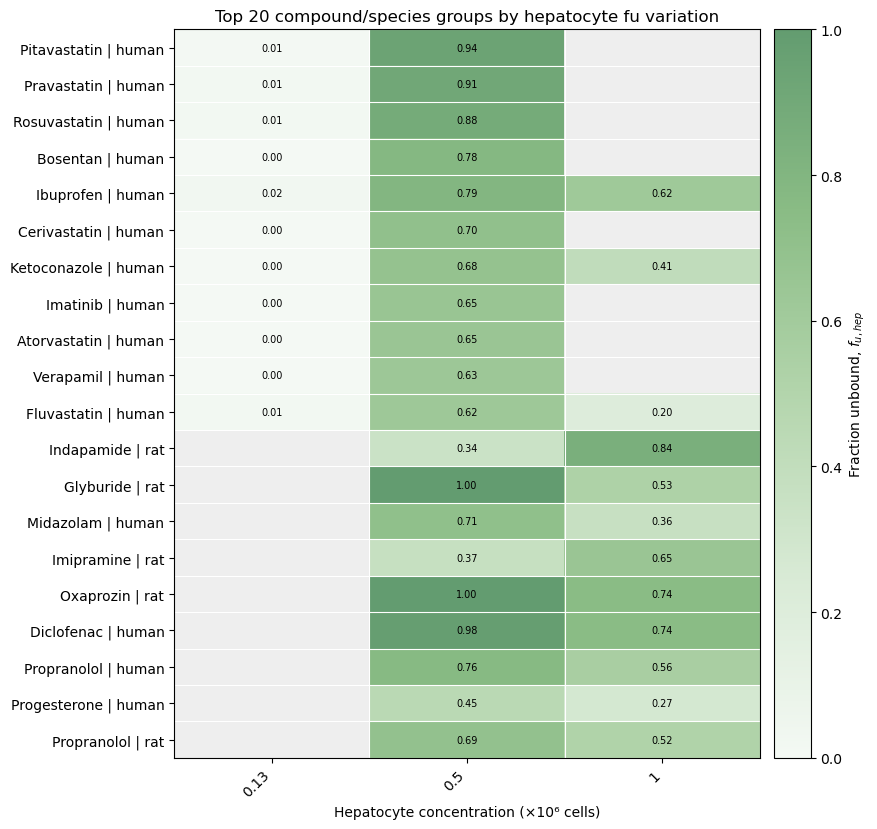

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

P = Path("./nonspecific_binding_dataset/Krumpholz_et_al_fu_dataset.xlsx")
TOP, MIN_CONC = 20, 2

df = pd.read_excel(P, sheet_name="Hepatocytes")
df.columns = df.columns.str.strip()
df["fu"] = pd.to_numeric(df["fu mean"], errors="coerce")
df["conc"] = pd.to_numeric(df["x10^6 cells"], errors="coerce")
df["group"] = df["Compound"].astype("string").str.strip() + " | " + df["species"].astype("string").str.strip()

bad = df[df["fu"].notna() & ~df["fu"].between(0, 1)]
print(f"fu outside 0–1: {len(bad)}")
if len(bad): print(bad[["Compound", "species", "fu mean", "x10^6 cells", "REF"]].to_string(index=False))

d = df[df["fu"].between(0, 1) & df["conc"].gt(0) & df["group"].notna()].copy()
a = d.groupby(["group", "conc"], as_index=False).agg(fu=("fu", "mean"), n_rep=("fu", "size"))

stats = a.groupby("group").agg(
    n_conc=("conc", "nunique"), n_raw=("n_rep", "sum"),
    conc_min=("conc", "min"), conc_max=("conc", "max"),
    fu_mean=("fu", "mean"), fu_sd=("fu", "std"),
    fu_min=("fu", "min"), fu_max=("fu", "max")
)
stats["conc_fold"] = stats["conc_max"] / stats["conc_min"]
stats["fu_range"] = stats["fu_max"] - stats["fu_min"]

top = (
    stats.query("n_conc >= @MIN_CONC")
    .sort_values(["fu_range", "n_conc"], ascending=[False, False])
    .head(TOP)
)
top.insert(0, "rank", range(1, len(top) + 1))

print(f"\nValid rows: {len(d)}")
print(f"Eligible groups with >= {MIN_CONC} cell concentrations: {(stats.n_conc >= MIN_CONC).sum()}")
print(f"\nTop {len(top)} ranked by fu range:\n")
print(top.round(3).to_string())

p = (
    a[a["group"].isin(top.index)]
    .pivot(index="group", columns="conc", values="fu")
    .reindex(top.index)
)

if len(p):
    fig, ax = plt.subplots(figsize=(max(9, .75*len(p.columns)), max(5, .42*len(p))))

    from matplotlib.colors import LinearSegmentedColormap

    cmap = LinearSegmentedColormap.from_list(
        "soft_green",
        ["#f4f9f4", "#d8ead5", "#b3d5ac", "#8abc85", "#639c70"],
    )
    cmap.set_bad("#eeeeee")
    im = ax.imshow(np.ma.masked_invalid(p.to_numpy()), aspect="auto",
                   vmin=0, vmax=1, cmap=cmap)

    ax.set_xticks(range(len(p.columns)), [f"{x:g}" for x in p.columns],
                  rotation=45, ha="right")
    ax.set_yticks(range(len(p)), p.index)
    ax.set(
        xlabel="Hepatocyte concentration (×10⁶ cells)",
        title=f"Top {len(top)} compound/species groups by hepatocyte fu variation"
    )

    for i in range(len(p)):
        for j in range(len(p.columns)):
            if pd.notna(v := p.iloc[i, j]):
                ax.text(
                        j, i, f"{v:.2f}",
                        ha="center", va="center",
                        fontsize=7, color="black"
                    )

    ax.set_xticks(np.arange(-.5, len(p.columns), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(p), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    cbar = fig.colorbar(im, ax=ax, pad=.02)
    cbar.set_label("Fraction unbound, $f_{u,hep}$")

    fig.tight_layout()
    plt.show()
else:
    print("No compound/species groups were measured at multiple cell concentrations.")